# Zero Coupon Note

Pays a fixed redemption at maturity and is issued at a discount. It has **no exposure to compute prices**: it is the funding leg inside every other note. Solving the redemption at par gives the note's yield (Treasury rate plus the issuer's credit spread); `1 - price` is the budget a capital-protected note can spend on options.

`payoff = redemption`

`R` = index at maturity / index at issue; amounts are fractions of notional.

Refresh data first with `uv run compute-options download && uv run compute-options aggregate`.

## 1. Parameters

Set any term to a number to fix it, or to `"solve"` to have the solver set it so the note is worth `ISSUE_PRICE - ISSUER_MARGIN` (at most one). With every term fixed, the note is priced as given and the table below shows the margin the issuer would earn (negative = the investor gets a bargain).

In [1]:
# --- Underlying -----------------------------------------------------------------
UNDERLYING = "H100_SXM"           # any instrument listed in the table below
SERIES = "composite_index"      # "composite_index" | "composite_level" | "benchmarks" (Ornn)

# --- Structure ------------------------------------------------------------------
TENOR = "12M"                    # "1M", "3M", "6M", "12M", "18M", "2Y", ...
TERMS = {
    "redemption": 'solve',  # paid at maturity; solved at par = the note's yield
}
ISSUE_PRICE = 1.00                # what the investor pays per unit notional
ISSUER_MARGIN = 0.000             # issuer's fee, used when a term is "solve"

# --- Expected return ------------------------------------------------------------
EXPECTED_DRIFT = 0.00             # your view of the index's annual drift (0 = forward is fair)

# --- Holding backtest -----------------------------------------------------------
HOLD_START = "2026-01-01"         # first note bought on the first priceable date on/after this
HOLD_END = None                   # None = latest data
ROLL = True                       # at maturity, reinvest in a new note with the same terms

# --- Market model ---------------------------------------------------------------
MARKET = {
    "vol_method": 'realized',  # "realized" | "ewma" | "ou"
    "vol_window": 90,          # calendar days of history used for vol
    "vol_horizon_days": 7,     # 7 = weekly returns (filters day-to-day noise)
    "vol_floor": 0.10,         # minimum vol used for pricing
    "forward_model": 'flat',   # "flat" (forward = spot) | "schwartz" (mean-reverting)
    "rate": None,              # None = US Treasury curve from FRED; or a flat rate, e.g. 0.04
    "issuer_spread": 0.01,     # issuer credit spread over Treasuries
    "min_history": 21,         # days of prices needed before the first note can be priced
}

In [2]:
%matplotlib inline
import pandas as pd

from compute_options.analytics import notebook as nb

pd.set_option("display.width", 160)
print(f"Underlyings in {SERIES}:")
nb.available_underlyings(SERIES)

Underlyings in composite_index:


,from,to,days,last ($/GPU-hr),vol (weekly returns)
instrument,,,,,
H100_SXM,2026-02-11,2026-09-26,222,3.757,19.06%
H200,2026-02-11,2026-09-26,170,4.533,14.02%
A100_SXM_80GB,2026-02-11,2026-09-26,170,2.261,17.58%
B200,2026-02-11,2026-09-26,170,7.020,18.41%
L40S,2026-02-11,2026-09-26,170,1.496,22.06%
A100_SXM_40GB,2026-02-11,2026-09-26,106,2.247,20.64%
RTX_PRO_6000,2026-07-06,2026-09-26,83,2.287,3.47%
L40,2026-07-07,2026-09-26,82,0.964,15.11%
RTX_A6000,2026-07-07,2026-09-26,82,0.584,2.17%


## 2. Pricing today

In [3]:
series = nb.load_underlying(UNDERLYING, SERIES)
priced = nb.price_structure(series, "zero_coupon", TENOR, TERMS, MARKET, ISSUE_PRICE, ISSUER_MARGIN)
display(nb.terms_table(priced))
display(nb.pricing_summary(priced))

,value
term,
kind,zero_coupon
tenor,1y (12M)
redemption (solved),105.61%


,value
valuation date,2026-09-26
initial fixing ($/GPU-hr),3.7570
forward at maturity ($/GPU-hr),3.7570
vol used (ATM),16.13%
issuer zero rate (incl. spread),5.46%
issue price,100.00%
fair value,100.00%
issuer margin (issue price - fair value),0.00%


### Expected return of holding to maturity

Buying at the issue price and holding to maturity. **APR** annualises the return to maturity: `(payoff / issue price) ^ (1 / tenor) - 1`.

- **Model:** the index ends lognormally distributed around its forward (plus `EXPECTED_DRIFT`), with the pricing vol. With zero drift the expected APR is roughly the issuer's funding rate less the margin: a fairly priced note doesn't beat cash on average unless you have a view on the index.
- **Historical:** the payoff applied to every realised move of the same length in the history (few, overlapping scenarios: illustrative only).

In [4]:
nb.expected_table(priced, series, EXPECTED_DRIFT)

,model (drift +0%/yr)
expected return (to maturity),5.61%
expected APR,5.61%
median APR,5.61%
5th percentile APR,5.61%
95th percentile APR,5.61%
probability of loss,0.00%
probability of full protection,100.00%


### Replication and Greeks

How the price is built from zero-coupon bonds, calls, puts and digitals, and its sensitivities per unit notional (delta per 1% index move, vega per vol point, theta per day, rho per bp).

In [5]:
display(nb.legs_table(priced))
display(nb.greeks_table(priced))

,amount,quantity,value
leg,,,
ZeroCouponBond,1.0561,1.0,1.0


,per unit notional
value,1.00000
delta,0.00000
delta_notional,0.00000
gamma,0.00000
vega,0.00000
theta,0.00016
rho,-0.00010


## 3. Payoff at maturity

Red dotted lines mark strikes, caps and barriers. The blue histogram shows the index moves that actually happened over the same tenor in the history.

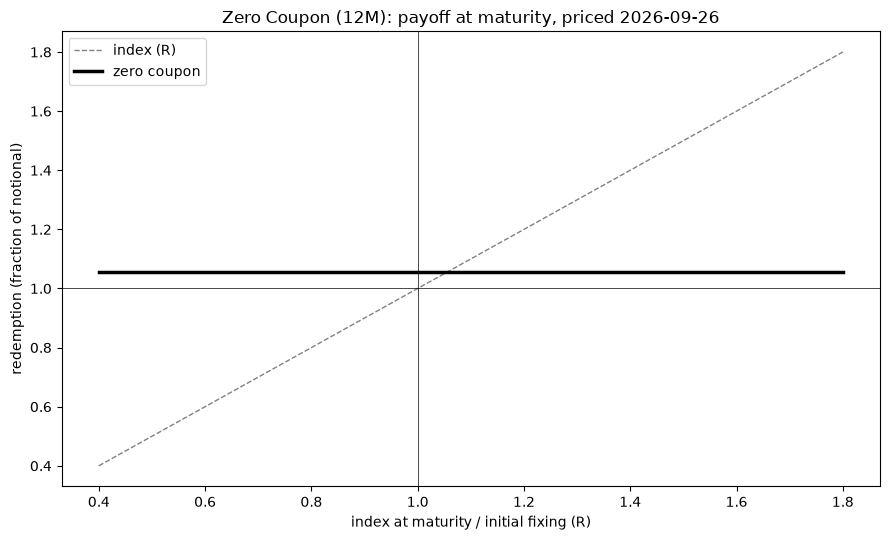

In [6]:
nb.plot_payoff(priced, series);

## 4. Backtest: holding the structure

Invest $1 in the note on the first date it can be priced on or after `HOLD_START` and hold it. At maturity the proceeds are reinvested in a new note on the same terms (a solved term is re-solved against that day's market). A note still alive at the end is marked to model value. The note is bought at the issue price but marked at fair value, so the value dips by the issuer's margin on each purchase.

Statistics are annualised over the holding period, with Sharpe and Sortino measured against the 3-month T-bill. The index is shown for comparison but is not investable. **The history is months long, so annualised figures are extrapolated from a short sample.**

In [7]:
res = nb.run_hold(series, priced, MARKET, ISSUER_MARGIN, HOLD_START, HOLD_END, ROLL)
print(f"Held {UNDERLYING} {TENOR} {priced.product.kind} from {res.start.date()} to {res.end.date()} "
      f"({len(res.notes)} note(s), average T-bill {res.rf:.2%})")
nb.holding_stats_table(res)

Held H100_SXM 12M zero_coupon from 2026-03-03 to 2026-09-26 (1 note(s), average T-bill 3.81%)


,structure (held),index (not investable),cash
total return,2.26%,17.05%,2.18%
APR (annualised),4.03%,32.00%,3.88%
annualised vol,0.35%,26.11%,0.01%
Sharpe,0.39,0.92,n/a
Sortino,0.53,1.55,n/a
max drawdown,-0.11%,-8.02%,0.00%
max drawdown (days),9,49,0
Calmar,35.13,3.99,n/a
best day,0.07%,7.10%,0.01%
worst day,-0.07%,-5.72%,0.01%


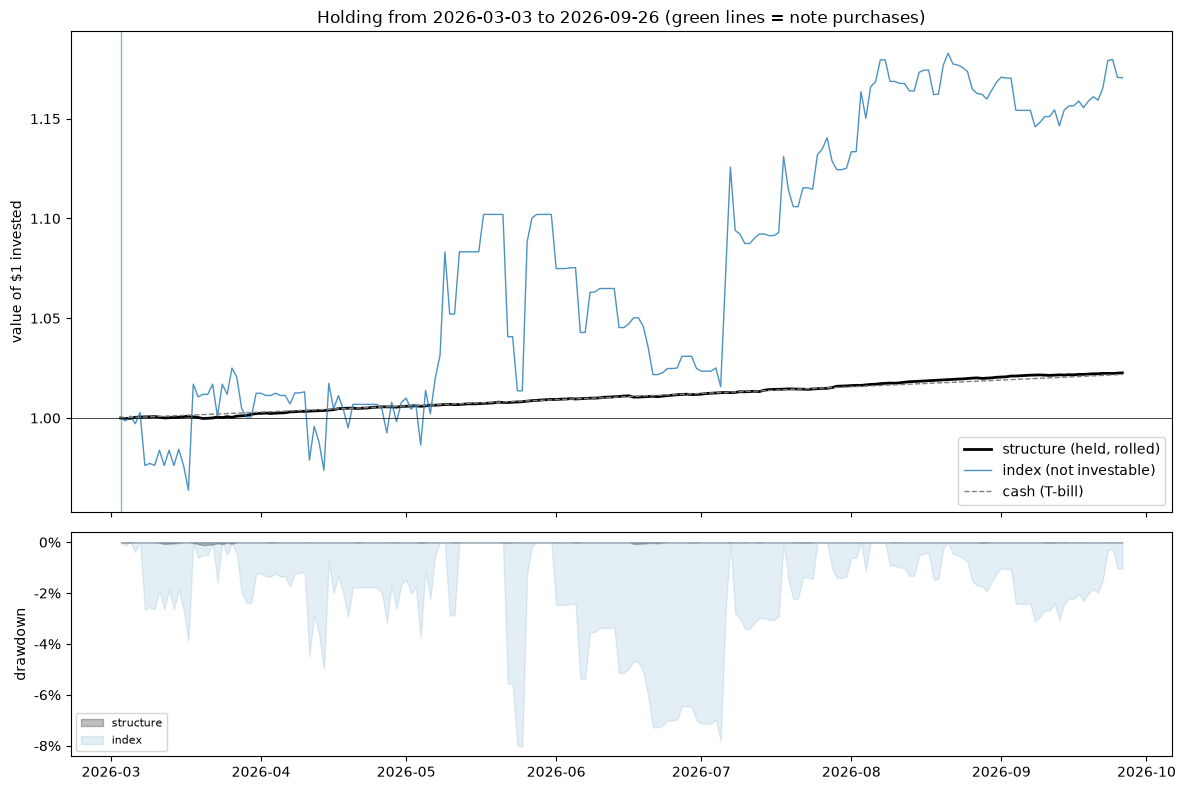

In [8]:
nb.plot_holding(res);

### Notes held

Each note bought, its terms, the investor's return, and the P&L of the issuer who sold it: unhedged (keeps the cash, pays the note), or delta-hedged with a futures contract on the index marked at the model forward (no public futures settlements exist yet).

In [9]:
nb.notes_held_table(res)

,matures,status,fixing ($/GPU-hr),index move,note return,note APR,issuer margin,issuer P&L unhedged,issuer P&L hedged
bought,,,,,,,,,
2026-03-03,2027-03-03,held (marked to model),3.2097,17.05%,2.26%,4.03%,0.00%,0.33%,0.52%
